/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


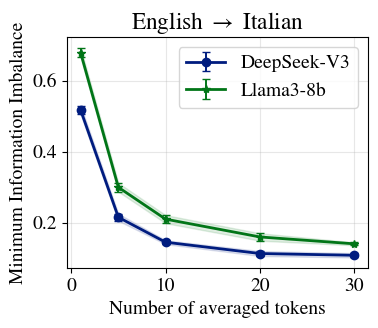

In [1]:
import os
import re
import sys
import glob
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../')
from utils import makefolder
from utils_plots import apply_plot_style, load_ii_curves, _min_token_length, get_layers

colors, markers, linestyles = apply_plot_style()
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()

# -----------------------
# Config
# -----------------------
model_specs = [
    ('deepseek', 'deepseek'),
    ('llama', 'llama8b'),
]



n_tokens_list = [1, 5, 10, 20, 30]

mask = 2
n_files = 500
batch_shuffle = 0
aux_A = 'source'
aux_B = 'target'
k_II = 10
Nbits = 0
seeds = list(range(5))

languageA = 'english'
languageB = 'italian'

base = '../results/santiago/'

fig, ax = plt.subplots(1, 1, figsize=(4, 3.5))

for model_id, (model, depth_key) in enumerate(model_specs):
    layers = get_layers(depth_key, depths)
    _model = 'DeepSeek-V3' if model =='deepseek' else 'Llama3-8b'

    min_ii_mean_ab = []
    min_ii_std_ab = []
    min_ii_mean_ba = []
    min_ii_std_ba = []
    argmin_rel_depth = []

    for n_tokens in n_tokens_list:
        avg_tokens = 0 if n_tokens == 1 else 1
        mean_ii, std_ii = load_ii_curves(
            base=base,
            batch_shuffle=batch_shuffle,
            model=model,
            aux_A=aux_A,
            aux_B=aux_B,
            n_files=n_files,
            min_token_length=35, #_min_token_length(model, languageA, languageB),
            languageA=languageA,
            languageB=languageB,
            mask=mask,
            k=k_II,
            Nbits=Nbits,
            seeds=seeds,
            n_tokens=n_tokens,
            avg_tokens=avg_tokens,
        )

        ab_curve = mean_ii[0]
        ab_std_curve = std_ii[0]
        ba_curve = mean_ii[1]
        ba_std_curve = std_ii[1]

        if len(ab_curve) != len(layers):
            raise ValueError(
                f'Layer mismatch for {model}, n_tokens={n_tokens}, avg_tokens={avg_tokens}: len(ab_curve)={len(ab_curve)} vs len(layers)={len(layers)}'
            )

        idx_ab = int(np.argmin(ab_curve))
        min_ii_mean_ab.append(float(ab_curve[idx_ab]))
        min_ii_std_ab.append(float(ab_std_curve[idx_ab]))
        argmin_rel_depth.append(float(layers[idx_ab] / depths[depth_key]))

        idx_ba = int(np.argmin(ba_curve))
        min_ii_mean_ba.append(float(ba_curve[idx_ba]))
        min_ii_std_ba.append(float(ba_std_curve[idx_ba]))

    min_ii_mean_ab = np.array(min_ii_mean_ab)
    min_ii_std_ab = np.array(min_ii_std_ab)
    min_ii_mean_ba = np.array(min_ii_mean_ba)
    min_ii_std_ba = np.array(min_ii_std_ba)

    if model == 'deepseek' and 0:
        os.makedirs('plot-data', exist_ok=True)
        mean_columns = np.vstack([n_tokens_list, min_ii_mean_ab, min_ii_mean_ba]).T
        std_columns = np.vstack([n_tokens_list, min_ii_std_ab, min_ii_std_ba]).T
        np.savetxt(
            'plot-data/deepseek-min-ii-vs-avg-tokens-mean.txt',
            mean_columns,
            header='n_tokens mean_ii_english_to_italian mean_ii_italian_to_english',
        )
        np.savetxt(
            'plot-data/deepseek-min-ii-vs-avg-tokens-std.txt',
            std_columns,
            header='n_tokens std_ii_english_to_italian std_ii_italian_to_english',
        )

    color = colors[model_id % len(colors)]
    marker = markers[model_id % len(markers)]

    ax.errorbar(
        n_tokens_list,
        min_ii_mean_ab,
        yerr=min_ii_std_ab,
        marker=marker,
        linestyle='-',
        color=color,
        linewidth=2,
        elinewidth=1.4,
        capsize=3,
        label=f'{_model}',
    )

    ax.fill_between(
        n_tokens_list,
        min_ii_mean_ab - min_ii_std_ab,
        min_ii_mean_ab + min_ii_std_ab,
        color=color,
        alpha=0.12,
    )

    # ax.errorbar(
    #     n_tokens_list,
    #     min_ii_mean_ba,
    #     yerr=min_ii_std_ba,
    #     marker=marker,
    #     linestyle='dotted',
    #     color=color,
    #     linewidth=2,
    #     elinewidth=1.2,
    #     capsize=3,
    #     label=f'{model} | Italian→English',
    # )

    # ax.fill_between(
    #     n_tokens_list,
    #     min_ii_mean_ba - min_ii_std_ba,
    #     min_ii_mean_ba + min_ii_std_ba,
    #     color=color,
    #     alpha=0.08,
    # )

        # y_offset = 8 + 12 * model_id + (6 if avg_tokens == 0 else 0)
        # for x, y, rel_d in zip(n_tokens_list, min_ii_mean, argmin_rel_depth):
        #     ax.annotate(
        #         f'{rel_d:.2f}',
        #         (x, y),
        #         textcoords='offset points',
        #         xytext=(0, y_offset),
        #         ha='center',
        #         fontsize=11,
        #         color=color,
        #     )

ax.set_xlabel('Number of averaged tokens')
ax.set_ylabel('Minimum Information Imbalance')
ax.set_title(r'English $\rightarrow$ Italian')
ax.grid(alpha=0.3)
ax.legend(loc='best')
fig.savefig('../results/figs/min_ii_vs_n_tokens.pdf', bbox_inches='tight')
plt.show()

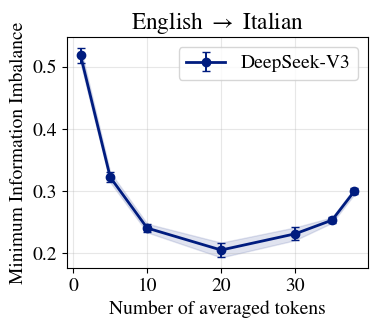

In [3]:
import os
import re
import sys
import glob
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../')
from utils import makefolder
from utils_plots import apply_plot_style, load_ii_curves, _min_token_length, get_layers

colors, markers, linestyles = apply_plot_style()
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()

# -----------------------
# Config
# -----------------------
model_specs = [
    ('deepseek', 'deepseek'),
    # ('llama', 'llama8b'),
]



n_tokens_list = [1, 5, 10, 20, 30,35,38]

mask = 2
n_files = 500
batch_shuffle = 0
aux_A = 'source'
aux_B = 'target'
k_II = 10
Nbits = 0
seeds = list(range(5))

languageA = 'english'
languageB = 'italian'

base = '../results/santiago/'

fig, ax = plt.subplots(1, 1, figsize=(4, 3.5))

for model_id, (model, depth_key) in enumerate(model_specs):
    layers = get_layers(depth_key, depths)
    _model = 'DeepSeek-V3' if model =='deepseek' else 'Llama3-8b'

    min_ii_mean_ab = []
    min_ii_std_ab = []
    min_ii_mean_ba = []
    min_ii_std_ba = []
    argmin_rel_depth = []

    for n_tokens in n_tokens_list:
        avg_tokens = 0 if n_tokens == 1 else 0
        mean_ii, std_ii = load_ii_curves(
            base=base,
            batch_shuffle=batch_shuffle,
            model=model,
            aux_A=aux_A,
            aux_B=aux_B,
            n_files=n_files,
            min_token_length=40, #_min_token_length(model, languageA, languageB),
            languageA=languageA,
            languageB=languageB,
            mask=mask,
            k=k_II,
            Nbits=Nbits,
            seeds=seeds,
            n_tokens=n_tokens,
            avg_tokens=avg_tokens,
        )

        ab_curve = mean_ii[0]
        ab_std_curve = std_ii[0]
        ba_curve = mean_ii[1]
        ba_std_curve = std_ii[1]

        if len(ab_curve) != len(layers):
            raise ValueError(
                f'Layer mismatch for {model}, n_tokens={n_tokens}, avg_tokens={avg_tokens}: len(ab_curve)={len(ab_curve)} vs len(layers)={len(layers)}'
            )

        idx_ab = int(np.argmin(ab_curve))
        min_ii_mean_ab.append(float(ab_curve[idx_ab]))
        min_ii_std_ab.append(float(ab_std_curve[idx_ab]))
        argmin_rel_depth.append(float(layers[idx_ab] / depths[depth_key]))

        idx_ba = int(np.argmin(ba_curve))
        min_ii_mean_ba.append(float(ba_curve[idx_ba]))
        min_ii_std_ba.append(float(ba_std_curve[idx_ba]))

    min_ii_mean_ab = np.array(min_ii_mean_ab)
    min_ii_std_ab = np.array(min_ii_std_ab)
    min_ii_mean_ba = np.array(min_ii_mean_ba)
    min_ii_std_ba = np.array(min_ii_std_ba)

    if model == 'deepseek' and 0:
        os.makedirs('plot-data', exist_ok=True)
        mean_columns = np.vstack([n_tokens_list, min_ii_mean_ab, min_ii_mean_ba]).T
        std_columns = np.vstack([n_tokens_list, min_ii_std_ab, min_ii_std_ba]).T
        np.savetxt(
            'plot-data/deepseek-min-ii-vs-avg-tokens-mean.txt',
            mean_columns,
            header='n_tokens mean_ii_english_to_italian mean_ii_italian_to_english',
        )
        np.savetxt(
            'plot-data/deepseek-min-ii-vs-avg-tokens-std.txt',
            std_columns,
            header='n_tokens std_ii_english_to_italian std_ii_italian_to_english',
        )

    color = colors[model_id % len(colors)]
    marker = markers[model_id % len(markers)]

    ax.errorbar(
        n_tokens_list,
        min_ii_mean_ab,
        yerr=min_ii_std_ab,
        marker=marker,
        linestyle='-',
        color=color,
        linewidth=2,
        elinewidth=1.4,
        capsize=3,
        label=f'{_model}',
    )

    ax.fill_between(
        n_tokens_list,
        min_ii_mean_ab - min_ii_std_ab,
        min_ii_mean_ab + min_ii_std_ab,
        color=color,
        alpha=0.12,
    )

    # ax.errorbar(
    #     n_tokens_list,
    #     min_ii_mean_ba,
    #     yerr=min_ii_std_ba,
    #     marker=marker,
    #     linestyle='dotted',
    #     color=color,
    #     linewidth=2,
    #     elinewidth=1.2,
    #     capsize=3,
    #     label=f'{model} | Italian→English',
    # )

    # ax.fill_between(
    #     n_tokens_list,
    #     min_ii_mean_ba - min_ii_std_ba,
    #     min_ii_mean_ba + min_ii_std_ba,
    #     color=color,
    #     alpha=0.08,
    # )

        # y_offset = 8 + 12 * model_id + (6 if avg_tokens == 0 else 0)
        # for x, y, rel_d in zip(n_tokens_list, min_ii_mean, argmin_rel_depth):
        #     ax.annotate(
        #         f'{rel_d:.2f}',
        #         (x, y),
        #         textcoords='offset points',
        #         xytext=(0, y_offset),
        #         ha='center',
        #         fontsize=11,
        #         color=color,
        #     )

ax.set_xlabel('Number of averaged tokens')
ax.set_ylabel('Minimum Information Imbalance')
ax.set_title(r'English $\rightarrow$ Italian')
ax.grid(alpha=0.3)
ax.legend(loc='best')
fig.savefig('../results/figs/min_ii_vs_n_tokens.pdf', bbox_inches='tight')
plt.show()